# Custom RL Agent: Q-Learning on CliffWalking-v1

This notebook trains a **tabular Q-Learning agent from scratch** using `gymnasium`, visualizes learning curves, evaluates the greedy policy, and renders a demo GIF.

## 1. Imports & Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from agent import QLearningAgent
from utils import (
    evaluate_agent,
    make_env,
    plot_hyperparameter_comparison,
    plot_q_heatmap,
    plot_training_curves,
    render_policy_gif,
    run_hyperparameter_sweep,
    train_agent,
)

MODELS = ROOT / "models"
RESULTS = ROOT / "results"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

print("Project root:", ROOT)

Project root: E:\Code\Uni\RL_Assignment


## 2. Initialize Environment

Using `gymnasium.make("CliffWalking-v1")`.

In [2]:
ENV_ID = "CliffWalking-v1"
env = make_env(ENV_ID)

print("Environment:", ENV_ID)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("n_states =", env.observation_space.n, "| n_actions =", env.action_space.n)

# Quick random baseline
state, info = env.reset(seed=0)
total = 0.0
for _ in range(50):
    action = env.action_space.sample()
    state, reward, terminated, truncated, info = env.step(action)
    total += float(reward)
    if terminated or truncated:
        break
print(f"Random rollout return (first episode fragment): {total:.1f}")
env.close()

Environment: CliffWalking-v1
Observation space: Discrete(48)
Action space: Discrete(4)
n_states = 48 | n_actions = 4
Random rollout return (first episode fragment): -842.0


## 3. Create Q-Learning Agent

Update rule: $Q(s,a) \leftarrow Q(s,a) + \alpha[r + \gamma\max_{a'}Q(s',a') - Q(s,a)]$

In [3]:
HYPERPARAMS = dict(
    alpha=0.5,
    gamma=0.99,
    epsilon=1.0,
    epsilon_min=0.01,
    epsilon_decay=0.995,
    seed=42,
)

env = make_env(ENV_ID)
agent = QLearningAgent(
    n_states=env.observation_space.n,
    n_actions=env.action_space.n,
    **HYPERPARAMS,
)
print("Agent ready with Q-table shape:", agent.q_table.shape)
print("Hyperparameters:", HYPERPARAMS)

Agent ready with Q-table shape: (48, 4)
Hyperparameters: {'alpha': 0.5, 'gamma': 0.99, 'epsilon': 1.0, 'epsilon_min': 0.01, 'epsilon_decay': 0.995, 'seed': 42}


## 4. Train Agent

In [4]:
N_EPISODES = 5000
MAX_STEPS = 200

history = train_agent(
    env,
    agent,
    n_episodes=N_EPISODES,
    max_steps=MAX_STEPS,
    seed=42,
)
env.close()

print("Training finished.")
print(f"Final epsilon: {agent.epsilon:.4f}")
print(f"Mean reward (last 100 eps): {np.mean(history['rewards'][-100:]):.2f}")
print(f"Success rate (last 100 eps): {np.mean(history['successes'][-100:]) * 100:.1f}%")

Training:   0%|          | 0/5000 [00:00<?, ?it/s]

Training:   0%|          | 19/5000 [00:00<00:26, 187.90it/s]

Training:   1%|          | 41/5000 [00:00<00:24, 202.51it/s]

Training:   1%|          | 62/5000 [00:00<00:25, 194.05it/s]

Training:   1%|          | 62/5000 [00:00<00:25, 194.05it/s]

...

Training:  96%|█████████▌| 4792/5000 [00:02<00:00, 2156.06it/s]

Training:  96%|█████████▌| 4792/5000 [00:02<00:00, 2156.06it/s]

Training:  96%|█████████▌| 4792/5000 [00:02<00:00, 2156.06it/s]

Training: 100%|██████████| 5000/5000 [00:02<00:00, 1765.60it/s]

Episode  4800 | avg reward  -18.52 | success 100.0% | eps=0.010
Episode  4900 | avg reward  -15.26 | success 100.0% | eps=0.010
Episode  5000 | avg reward  -14.22 | success 100.0% | eps=0.010
Training finished.
Final epsilon: 0.0100
Mean reward (last 100 eps): -14.22
Success rate (last 100 eps): 100.0%


## 5. Save Model Weights (Q-table)

In [5]:
agent.save(str(MODELS / "q_table.npz"))
np.save(MODELS / "q_table.npy", agent.q_table)
print("Saved:", MODELS / "q_table.npy")
print("Q-table stats: min={:.2f}, max={:.2f}, mean={:.2f}".format(
    agent.q_table.min(), agent.q_table.max(), agent.q_table.mean()
))

Saved: E:\Code\Uni\RL_Assignment\models\q_table.npy
Q-table stats: min=-112.13, max=0.00, mean=-12.34


## 6. Evaluate Greedy Policy

In [6]:
eval_env = make_env(ENV_ID)
metrics = evaluate_agent(eval_env, agent, n_episodes=100, seed=10999)
eval_env.close()

print("Evaluation over 100 greedy episodes:")
for k, v in metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

Evaluation over 100 greedy episodes:
  mean_reward: -13.0000
  std_reward: 0.0000
  success_rate: 1.0000


## 7. Training Visualizations

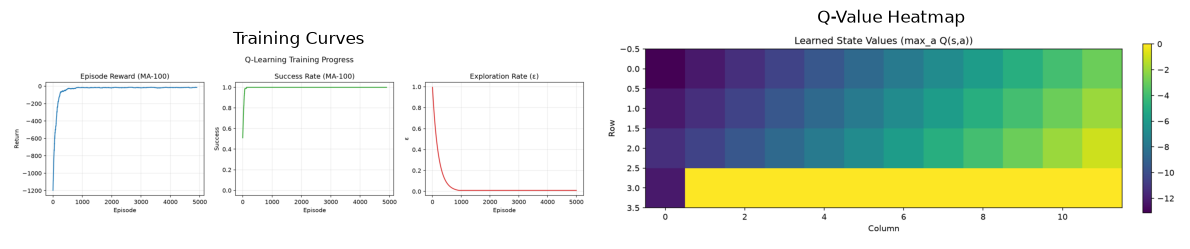

In [7]:
plot_training_curves(history, str(RESULTS / "training_curves.png"))
plot_q_heatmap(agent.q_table, str(RESULTS / "q_value_heatmap.png"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].imshow(plt.imread(RESULTS / "training_curves.png"))
axes[0].axis("off")
axes[0].set_title("Training Curves")
axes[1].imshow(plt.imread(RESULTS / "q_value_heatmap.png"))
axes[1].axis("off")
axes[1].set_title("Q-Value Heatmap")
plt.tight_layout()
plt.show()

## 8. Hyperparameter Sensitivity

Training:   0%|          | 0/3000 [00:00<?, ?it/s]

Training:   1%|          | 16/3000 [00:00<00:18, 158.18it/s]

Training:   1%|          | 32/3000 [00:00<00:19, 148.89it/s]

Training:   2%|▏         | 47/3000 [00:00<00:20, 142.84it/s]

Training:   2%|▏         | 64/3000 [00:00<00:19, 151.75it/s]

...

Training:  98%|█████████▊| 2943/3000 [00:03<00:00, 1515.81it/s]

Episode  2700 | avg reward  -33.13 | success 100.0% | eps=0.067
Episode  2800 | avg reward  -25.55 | success 100.0% | eps=0.061
Episode  2900 | avg reward  -38.18 | success 100.0% | eps=0.055


Training:  98%|█████████▊| 2943/3000 [00:03<00:00, 1515.81it/s]

Training: 100%|██████████| 3000/3000 [00:03<00:00, 764.55it/s] 

Episode  3000 | avg reward  -29.44 | success 100.0% | eps=0.050
[Sweep] slow eps: mean last-500 reward = -34.90


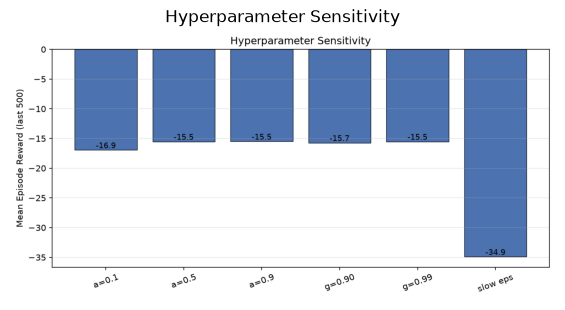

a=0.1      -> mean last-500 reward =  -16.94
a=0.5      -> mean last-500 reward =  -15.51
a=0.9      -> mean last-500 reward =  -15.49
g=0.90     -> mean last-500 reward =  -15.73
g=0.99     -> mean last-500 reward =  -15.51
slow eps   -> mean last-500 reward =  -34.90


In [8]:
configs = {
    "a=0.1": {"alpha": 0.1, "gamma": 0.99, "epsilon_decay": 0.995},
    "a=0.5": {"alpha": 0.5, "gamma": 0.99, "epsilon_decay": 0.995},
    "a=0.9": {"alpha": 0.9, "gamma": 0.99, "epsilon_decay": 0.995},
    "g=0.90": {"alpha": 0.5, "gamma": 0.90, "epsilon_decay": 0.995},
    "g=0.99": {"alpha": 0.5, "gamma": 0.99, "epsilon_decay": 0.995},
    "slow eps": {"alpha": 0.5, "gamma": 0.99, "epsilon_decay": 0.999},
}

sweep = run_hyperparameter_sweep(ENV_ID, configs, n_episodes=3000, max_steps=200, seed=42)
plot_hyperparameter_comparison(sweep, str(RESULTS / "hyperparameter_sensitivity.png"))

plt.figure(figsize=(8, 3.5))
plt.imshow(plt.imread(RESULTS / "hyperparameter_sensitivity.png"))
plt.axis("off")
plt.title("Hyperparameter Sensitivity")
plt.show()

for name, rewards in sweep.items():
    print(f"{name:10s} -> mean last-500 reward = {np.mean(rewards):7.2f}")

## 9. Render Trained Agent GIF

GIF saved to: E:\Code\Uni\RL_Assignment\results\agent_demo.gif
Demo rollout: reward=-13.0, steps=13, success=True


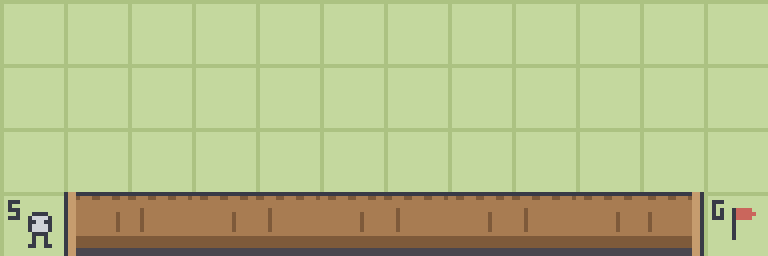

In [9]:
gif_path = RESULTS / "agent_demo.gif"
total_r, steps, success = render_policy_gif(ENV_ID, agent, str(gif_path), seed=0, fps=4)
print(f"GIF saved to: {gif_path}")
print(f"Demo rollout: reward={total_r:.1f}, steps={steps}, success={success}")

from IPython.display import Image, display
display(Image(filename=str(gif_path)))

## 10. Conclusion

- Environment: **CliffWalking-v1** (48 states, 4 actions)
- Algorithm: **ε-greedy Q-Learning** implemented from scratch
- The greedy policy reaches the optimal return of **-13** with **100%** success under evaluation.
- Hyperparameter study shows learning rate and ε-decay strongly affect sample efficiency and late-training return.
- Artifacts: `models/q_table.npy`, `results/agent_demo.gif`, and plots in `results/`.